In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

predictions_dir = project_root / "outputs" / "predictions"
metrics_dir = project_root / "outputs" / "metrics"
figures_dir = project_root / "outputs" / "figures"

for folder in [metrics_dir, figures_dir]:
    folder.mkdir(parents=True, exist_ok=True)

scored_news = pd.read_csv(
    predictions_dir / "tsla_scored_headlines_2019_2023.csv"
)

scored_news["Date"] = pd.to_datetime(
    scored_news["Date"],
    utc=True
)

scored_news = scored_news.sort_values("Date").reset_index(drop=True)

AS_OF_DATE = scored_news["Date"].max()

print("Company: TSLA")
print("Headlines:", len(scored_news))
print("Historical coverage:", scored_news["Date"].min(), "to", AS_OF_DATE)

Company: TSLA
Headlines: 872
Historical coverage: 2019-07-01 00:00:00+00:00 to 2023-12-16 22:00:00+00:00


In [3]:
# --------------------------------------------------
# 2. Add recency weights
# --------------------------------------------------

HALF_LIFE_DAYS = 30

scored_news["age_days"] = (
    AS_OF_DATE - scored_news["Date"]
).dt.total_seconds() / 86400

# A headline published on the as-of date has weight 1.
# Its influence halves every 30 days.
scored_news["recency_weight"] = 2 ** (
    -scored_news["age_days"] / HALF_LIFE_DAYS
)

display(
    scored_news[
        [
            "Date",
            "Article_title",
            "predicted_label",
            "sentiment_score",
            "recency_weight"
        ]
    ].tail(10)
)

,Date,Article_title,predicted_label,sentiment_score,recency_weight
862,2023-12-07 00:00:00+00:00,Tata Motors lobbies India not to lower EV impo...,neutral,0.057546,0.795230
863,2023-12-08 00:00:00+00:00,Vanguard Total World Stock ETF Experiences Big...,positive,0.810482,0.813818
864,2023-12-09 00:00:00+00:00,3 Stocks Transforming the Electric Vehicle Cha...,positive,0.769468,0.832840
865,2023-12-10 00:00:00+00:00,Stellantis Just Passed Ford and GM in the Elec...,neutral,0.111362,0.852307
866,2023-12-11 00:00:00+00:00,3 High-Voltage Battery Stocks to Ride EV Growt...,positive,0.914388,0.872228
867,2023-12-12 00:00:00+00:00,TSLA Factor-Based Stock Analysis,neutral,0.012238,0.892616
868,2023-12-13 00:00:00+00:00,Why Tesla's Cheap (2024 Outlook),neutral,0.035566,0.913480
869,2023-12-14 00:00:00+00:00,Tesla Stock Can Soar in 2024 if It Does These ...,neutral,0.059746,0.934831
870,2023-12-15 00:00:00+00:00,Elon Musk says oil and gas should not be demon...,neutral,-0.017325,0.956682
871,2023-12-16 22:00:00+00:00,Scotiabank's Mexico bet eyeing $1.6 trillion N...,neutral,0.038845,1.000000


In [4]:
# --------------------------------------------------
# 3. Compare historical windows
# --------------------------------------------------

WINDOWS = {
    "Last 30 days": 30,
    "Last 180 days": 180,
    "Last 365 days": 365,
    "All available history": None
}

window_results = []

for window_name, days in WINDOWS.items():

    if days is None:
        window_data = scored_news.copy()
    else:
        window_start = AS_OF_DATE - pd.Timedelta(days=days)

        window_data = scored_news[
            scored_news["Date"] >= window_start
        ].copy()

    if len(window_data) == 0:
        continue

    weighted_score = np.average(
        window_data["sentiment_score"],
        weights=window_data["recency_weight"]
    )

    label_percentages = (
        window_data["predicted_label"]
        .value_counts(normalize=True)
        .mul(100)
    )

    window_results.append(
        {
            "window": window_name,
            "headline_count": len(window_data),
            "unweighted_sentiment": (
                window_data["sentiment_score"].mean()
            ),
            "recency_weighted_sentiment": weighted_score,
            "positive_percent": label_percentages.get("positive", 0),
            "neutral_percent": label_percentages.get("neutral", 0),
            "negative_percent": label_percentages.get("negative", 0)
        }
    )

window_summary = pd.DataFrame(window_results)

numeric_columns = [
    "unweighted_sentiment",
    "recency_weighted_sentiment",
    "positive_percent",
    "neutral_percent",
    "negative_percent"
]

window_summary[numeric_columns] = window_summary[
    numeric_columns
].round(4)

window_summary

,window,headline_count,unweighted_sentiment,recency_weighted_sentiment,positive_percent,neutral_percent,negative_percent
0,Last 30 days,30,0.1238,0.1474,16.6667,76.6667,6.6667
1,Last 180 days,178,0.0655,0.1019,15.1685,73.5955,11.2360
2,Last 365 days,362,0.0400,0.1017,16.0221,69.3370,14.6409
3,All available history,872,0.0238,0.1017,14.4495,69.3807,16.1697


In [5]:
# --------------------------------------------------
# 4. Save window summary
# --------------------------------------------------

window_summary.to_csv(
    metrics_dir / "tsla_sentiment_window_summary.csv",
    index=False
)

print("Saved window summary.")

Saved window summary.


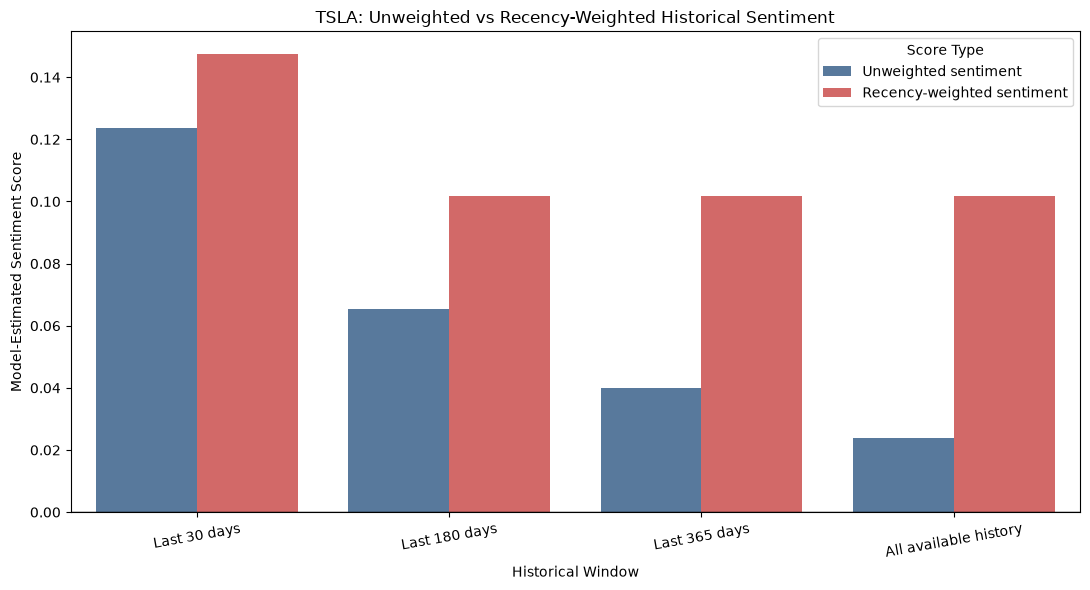

In [6]:
# --------------------------------------------------
# 5. Plot weighted vs unweighted sentiment
# --------------------------------------------------

plot_data = window_summary.melt(
    id_vars="window",
    value_vars=[
        "unweighted_sentiment",
        "recency_weighted_sentiment"
    ],
    var_name="score_type",
    value_name="sentiment_score"
)

plot_data["score_type"] = plot_data["score_type"].replace(
    {
        "unweighted_sentiment": "Unweighted sentiment",
        "recency_weighted_sentiment": "Recency-weighted sentiment"
    }
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=plot_data,
    x="window",
    y="sentiment_score",
    hue="score_type",
    palette=["#4C78A8", "#E45756"]
)

plt.axhline(0, color="black", linewidth=1)
plt.title(
    "TSLA: Unweighted vs Recency-Weighted Historical Sentiment"
)
plt.xlabel("Historical Window")
plt.ylabel("Model-Estimated Sentiment Score")
plt.xticks(rotation=10)
plt.legend(title="Score Type")

plt.tight_layout()

plt.savefig(
    figures_dir / "tsla_weighted_vs_unweighted_sentiment.png",
    dpi=200
)

plt.show()

In [7]:
# --------------------------------------------------
# 6. Create a 30-day rolling sentiment trend
# --------------------------------------------------

daily_news = (
    scored_news
    .assign(day=scored_news["Date"].dt.floor("D"))
    .groupby("day")
    .agg(
        daily_sentiment_sum=("sentiment_score", "sum"),
        headline_count=("sentiment_score", "size")
    )
    .sort_index()
)

daily_index = pd.date_range(
    start=daily_news.index.min(),
    end=daily_news.index.max(),
    freq="D",
    tz="UTC"
)

daily_news = daily_news.reindex(
    daily_index,
    fill_value=0
)

daily_news.index.name = "Date"

daily_news["rolling_30d_headlines"] = (
    daily_news["headline_count"]
    .rolling(window=30, min_periods=1)
    .sum()
)

daily_news["rolling_30d_sentiment_sum"] = (
    daily_news["daily_sentiment_sum"]
    .rolling(window=30, min_periods=1)
    .sum()
)

daily_news["rolling_30d_sentiment"] = np.where(
    daily_news["rolling_30d_headlines"] > 0,
    daily_news["rolling_30d_sentiment_sum"]
    / daily_news["rolling_30d_headlines"],
    np.nan
)

display(daily_news.tail())

,daily_sentiment_sum,headline_count,rolling_30d_headlines,rolling_30d_sentiment_sum,rolling_30d_sentiment
Date,,,,,
2023-12-12 00:00:00+00:00,0.012238,1,30.0,3.257107,0.108570
2023-12-13 00:00:00+00:00,0.035566,1,30.0,3.244946,0.108165
2023-12-14 00:00:00+00:00,0.059746,1,30.0,3.296099,0.109870
2023-12-15 00:00:00+00:00,-0.017325,1,30.0,3.689150,0.122972
2023-12-16 00:00:00+00:00,0.038845,1,30.0,3.712966,0.123766


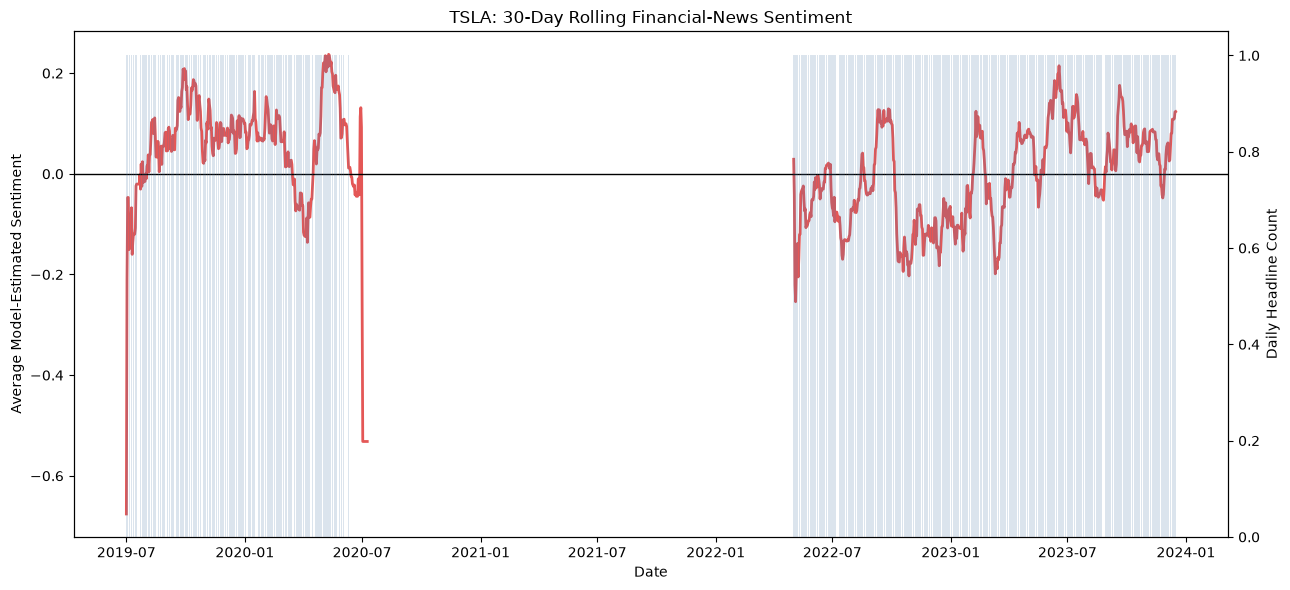

In [8]:
# --------------------------------------------------
# 7. Plot rolling sentiment and news volume
# --------------------------------------------------

fig, left_axis = plt.subplots(figsize=(13, 6))

left_axis.plot(
    daily_news.index,
    daily_news["rolling_30d_sentiment"],
    color="#E45756",
    linewidth=2,
    label="30-day rolling sentiment"
)

left_axis.axhline(
    0,
    color="black",
    linewidth=1
)

left_axis.set_title(
    "TSLA: 30-Day Rolling Financial-News Sentiment"
)

left_axis.set_xlabel("Date")
left_axis.set_ylabel("Average Model-Estimated Sentiment")

right_axis = left_axis.twinx()

right_axis.bar(
    daily_news.index,
    daily_news["headline_count"],
    color="#4C78A8",
    alpha=0.20,
    label="Daily headline count"
)

right_axis.set_ylabel("Daily Headline Count")

fig.tight_layout()

plt.savefig(
    figures_dir / "tsla_30day_rolling_sentiment.png",
    dpi=200
)

plt.show()

In [9]:
# --------------------------------------------------
# 8. Show latest headlines for your presentation
# --------------------------------------------------

latest_headlines = scored_news[
    [
        "Date",
        "Article_title",
        "Publisher",
        "predicted_label",
        "confidence",
        "sentiment_score"
    ]
].tail(15).copy()

latest_headlines["confidence"] = (
    latest_headlines["confidence"].round(3)
)

latest_headlines["sentiment_score"] = (
    latest_headlines["sentiment_score"].round(3)
)

display(latest_headlines)

,Date,Article_title,Publisher,predicted_label,confidence,sentiment_score
857,2023-12-02 00:00:00+00:00,Tap Into the Same Investment that Made Elon Mu...,NaN,neutral,0.519,0.460
858,2023-12-03 00:00:00+00:00,China's BYD says will keep reward system for s...,NaN,neutral,0.803,0.165
859,2023-12-04 00:00:00+00:00,"The 7 Best Ways to Invest $1,000 in the Stock ...",NaN,neutral,0.876,0.109
860,2023-12-05 00:00:00+00:00,"Pre-Market Most Active for Dec 5, 2023 : NIO, ...",NaN,neutral,0.978,0.009
861,2023-12-06 00:00:00+00:00,Norway union joins Tesla blockade in support f...,NaN,neutral,0.628,0.299
862,2023-12-07 00:00:00+00:00,Tata Motors lobbies India not to lower EV impo...,NaN,neutral,0.834,0.058
863,2023-12-08 00:00:00+00:00,Vanguard Total World Stock ETF Experiences Big...,NaN,positive,0.830,0.810
864,2023-12-09 00:00:00+00:00,3 Stocks Transforming the Electric Vehicle Cha...,NaN,positive,0.783,0.769
865,2023-12-10 00:00:00+00:00,Stellantis Just Passed Ford and GM in the Elec...,NaN,neutral,0.823,0.111
866,2023-12-11 00:00:00+00:00,3 High-Voltage Battery Stocks to Ride EV Growt...,NaN,positive,0.930,0.914


In [11]:
# --------------------------------------------------
# 9. Print a presentation-ready summary
# --------------------------------------------------

latest_window = window_summary[
    window_summary["window"] == "Last 30 days"
].iloc[0]

all_history_window = window_summary[
    window_summary["window"] == "All available history"
].iloc[0]

print(f"Historical as-of date: {AS_OF_DATE.date()}")

print(
    "\nLast 30 days recency-weighted sentiment:",
    round(
        latest_window["recency_weighted_sentiment"],
        3
    )
)

print(
    "All available history recency-weighted sentiment:",
    round(
        all_history_window["recency_weighted_sentiment"],
        3
    )
)

Historical as-of date: 2023-12-16

Last 30 days recency-weighted sentiment: 0.147
All available history recency-weighted sentiment: 0.102
